<a href="https://colab.research.google.com/github/fuger-tw/2026_DL_hws/blob/main/hw4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import tensorflow as tf
from ipywidgets import interact_manual
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

font_path = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not font_path.exists():
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
chinese_font = font_manager.FontProperties(fname=font_path)

tf.keras.utils.set_random_seed(42)
class_names = np.array(["飛機", "汽車", "鳥", "貓", "鹿", "狗", "青蛙", "馬", "船", "卡車"])
num_classes = len(class_names)

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.cifar10.load_data()
print(f"原始訓練資料：圖片 {x_train_raw.shape}，標籤 {y_train_raw.shape}")
print(f"原始測試資料：圖片 {x_test_raw.shape}，標籤 {y_test_raw.shape}")

y_train_ids = y_train_raw.ravel()
y_test_ids = y_test_raw.ravel()
train_indices, val_indices = train_test_split(
    np.arange(len(y_train_ids)),
    test_size=0.20,
    stratify=y_train_ids,
    random_state=42,
)

x_train = x_train_raw[train_indices].astype(np.float32) / 255.0
x_val = x_train_raw[val_indices].astype(np.float32) / 255.0
x_test = x_test_raw.astype(np.float32) / 255.0
y_train = tf.keras.utils.to_categorical(y_train_ids[train_indices], num_classes)
y_val = tf.keras.utils.to_categorical(y_train_ids[val_indices], num_classes)
y_test = tf.keras.utils.to_categorical(y_test_ids, num_classes)

for name, images, labels in [
    ("訓練資料", x_train, y_train),
    ("驗證資料", x_val, y_val),
    ("測試資料", x_test, y_test),
]:
    print(f"預處理後{name}：圖片 {images.shape}，one-hot 標籤 {labels.shape}")

原始訓練資料：圖片 (50000, 32, 32, 3)，標籤 (50000, 1)
原始測試資料：圖片 (10000, 32, 32, 3)，標籤 (10000, 1)
預處理後訓練資料：圖片 (40000, 32, 32, 3)，one-hot 標籤 (40000, 10)
預處理後驗證資料：圖片 (10000, 32, 32, 3)，one-hot 標籤 (10000, 10)
預處理後測試資料：圖片 (10000, 32, 32, 3)，one-hot 標籤 (10000, 10)


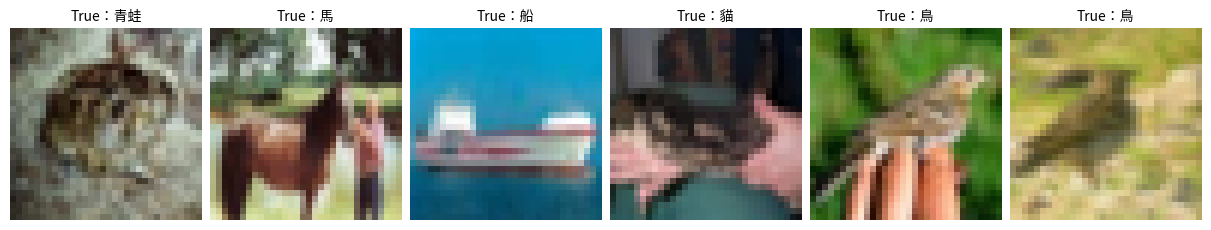

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.6), layout="constrained")
for ax, index in zip(axes, train_indices[:6]):
    ax.imshow(x_train_raw[index])
    ax.set_title(f"True：{class_names[y_train_ids[index]]}", fontproperties=chinese_font)
    ax.axis("off")
plt.show()

In [4]:
layers = tf.keras.layers
model = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3), name="image"),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1"),
    layers.Dropout(0.3, name="dropout1"),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv2"),
    layers.MaxPooling2D((2, 2), name="pool1"),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv3"),
    layers.Dropout(0.3, name="dropout2"),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv4"),
    layers.MaxPooling2D((2, 2), name="pool2"),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv5"),
    layers.Dropout(0.3, name="dropout3"),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv6"),
    layers.MaxPooling2D((2, 2), name="pool3"),
    layers.Flatten(name="flatten"),
    layers.Dropout(0.3, name="dropout4"),
    layers.Dense(2500, activation="relu", name="dense1"),
    layers.Dropout(0.3, name="dropout5"),
    layers.Dense(1500, activation="relu", name="dense2"),
    layers.Dropout(0.3, name="dropout6"),
    layers.Dense(num_classes, activation="softmax", name="class_probabilities"),
], name="cifar10_cnn_19layers")
model.summary()

Model: "cifar10_cnn_19layers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout4 (Dropout)              │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout5 (Dropout)              │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense2 (Dense)                  │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout6 (Dropout)              │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
batch_size = 128
epochs = 50

batch_tensor = tf.convert_to_tensor(x_train[:batch_size])
print(f"模型輸入：{tuple(batch_tensor.shape)}")
for number, layer in enumerate(model.layers, start=1):
    input_shape = tuple(batch_tensor.shape)
    batch_tensor = layer(batch_tensor)
    print(f"{number:02d} {layer.name:21s}  {str(input_shape):21s} → {tuple(batch_tensor.shape)}")
print(f"批次 one-hot 標籤：{y_train[:batch_size].shape}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
)

模型輸入：(128, 32, 32, 3)
01 conv1                  (128, 32, 32, 3)      → (128, 32, 32, 32)
02 dropout1               (128, 32, 32, 32)     → (128, 32, 32, 32)
03 conv2                  (128, 32, 32, 32)     → (128, 32, 32, 32)
04 pool1                  (128, 32, 32, 32)     → (128, 16, 16, 32)
05 conv3                  (128, 16, 16, 32)     → (128, 16, 16, 64)
06 dropout2               (128, 16, 16, 64)     → (128, 16, 16, 64)
07 conv4                  (128, 16, 16, 64)     → (128, 16, 16, 64)
08 pool2                  (128, 16, 16, 64)     → (128, 8, 8, 64)
09 conv5                  (128, 8, 8, 64)       → (128, 8, 8, 128)
10 dropout3               (128, 8, 8, 128)      → (128, 8, 8, 128)
11 conv6                  (128, 8, 8, 128)      → (128, 8, 8, 128)
12 pool3                  (128, 8, 8, 128)      → (128, 4, 4, 128)
13 flatten                (128, 4, 4, 128)      → (128, 2048)
14 dropout4               (128, 2048)           → (128, 2048)
15 dense1                 (128, 2048)       

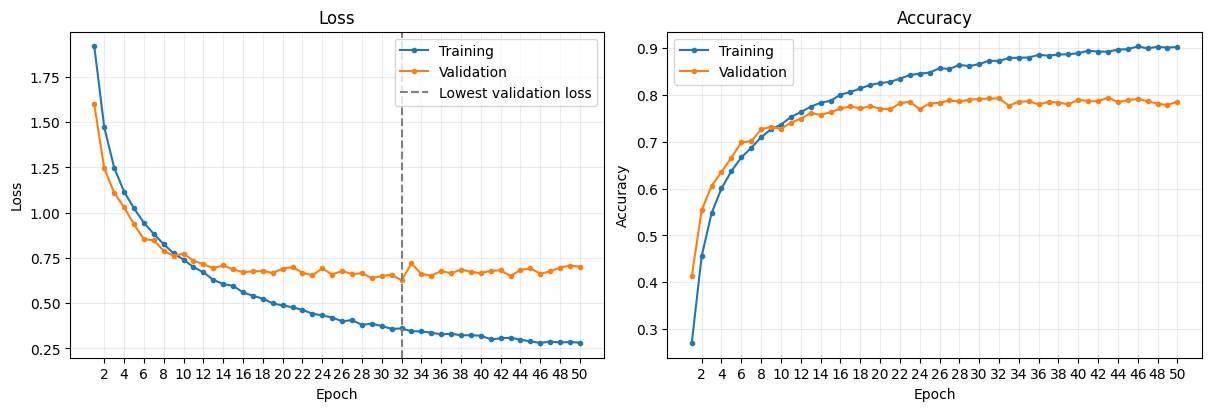

驗證 loss 最低（第 32 輪）｜訓練 loss 0.3605、驗證 loss 0.6264｜訓練 accuracy 87.30%、驗證 accuracy 79.27%
訓練結束（第 50 輪）｜訓練 loss 0.2822、驗證 loss 0.7019｜訓練 accuracy 90.29%、驗證 accuracy 78.61%
訓練 loss 下降、驗證 loss 回升，出現過擬合的跡象。可從折線圖確認差距是否持續擴大。


In [6]:
metrics = history.history
epoch_numbers = np.arange(1, len(metrics["loss"]) + 1)
best_idx = int(np.argmin(metrics["val_loss"]))
last_idx = len(epoch_numbers) - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(epoch_numbers, metrics[key], marker="o", markersize=3, label="Training")
    ax.plot(epoch_numbers, metrics[f"val_{key}"], marker="o", markersize=3, label="Validation")
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=title,
        xticks=np.arange(2, len(epoch_numbers) + 1, 2),
    )
    ax.grid(alpha=0.25)
axes[0].axvline(epoch_numbers[best_idx], color="gray", linestyle="--", label="Lowest validation loss")
for ax in axes:
    ax.legend()
plt.show()

for label, idx in [("驗證 loss 最低", best_idx), ("訓練結束", last_idx)]:
    print(
        f"{label}（第 {epoch_numbers[idx]} 輪）｜"
        f"訓練 loss {metrics['loss'][idx]:.4f}、驗證 loss {metrics['val_loss'][idx]:.4f}｜"
        f"訓練 accuracy {metrics['accuracy'][idx]:.2%}、"
        f"驗證 accuracy {metrics['val_accuracy'][idx]:.2%}"
    )

if (
    best_idx < last_idx
    and metrics["loss"][last_idx] < metrics["loss"][best_idx]
    and metrics["val_loss"][last_idx] > metrics["val_loss"][best_idx]
):
    print("訓練 loss 下降、驗證 loss 回升，出現過擬合的跡象。可從折線圖確認差距是否持續擴大。")
else:
    print("這兩輪的比較未顯示典型的過擬合跡象。請一併查看完整曲線是否有持續分離。")

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
print(f"測試圖片數量：{len(x_test):,}")
print(f"測試 loss：{test_loss:.4f}")
print(f"測試準確率：{test_accuracy:.2%}")

測試圖片數量：10,000
測試 loss：0.7129
測試準確率：78.18%


79/79 ━━━━━━━━━━━━━━━━━━━━ 23s 288ms/step
已完成 10,000 張測試圖片的預測。


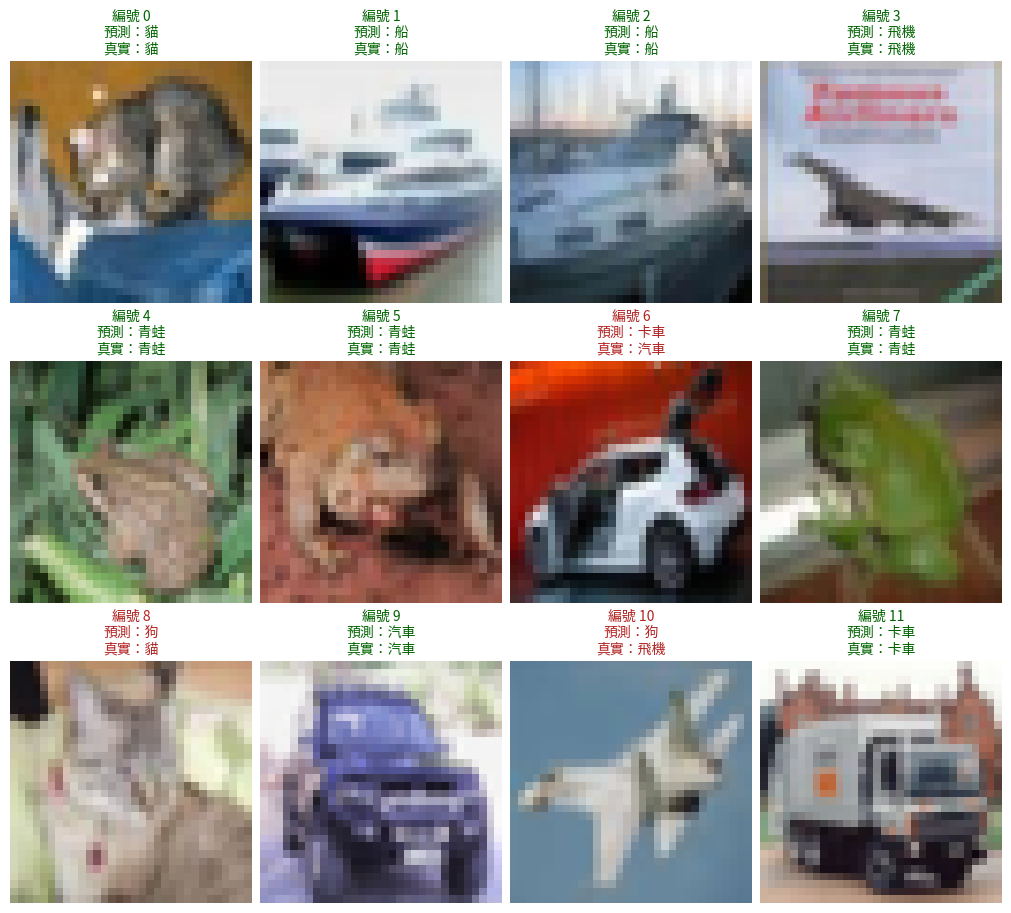

In [8]:
test_probabilities = model.predict(x_test, batch_size=batch_size, verbose=1)
y_pred_ids = test_probabilities.argmax(axis=1)
assert len(y_pred_ids) == len(y_test_ids) == 10_000
true_names = class_names[y_test_ids]
predicted_names = class_names[y_pred_ids]
print(f"已完成 {len(predicted_names):,} 張測試圖片的預測。")


def show_test_image(ax, index):
    ax.imshow(x_test_raw[index])
    ax.set_title(
        f"編號 {index}\n預測：{predicted_names[index]}\n真實：{true_names[index]}",
        color="darkgreen" if y_pred_ids[index] == y_test_ids[index] else "firebrick",
        fontproperties=chinese_font,
    )
    ax.axis("off")


fig, axes = plt.subplots(3, 4, figsize=(10, 9), layout="constrained")
for ax, index in zip(axes.flat, range(12)):
    show_test_image(ax, index)
plt.show()

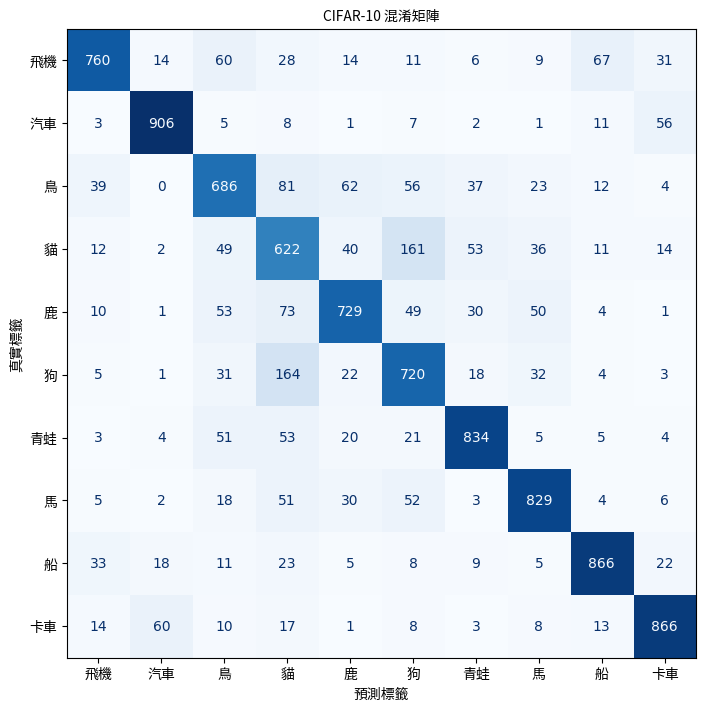

In [9]:
cm = confusion_matrix(y_test_ids, y_pred_ids, labels=np.arange(num_classes))
assert cm.sum() == len(x_test)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False,
)
ax.set_title("CIFAR-10 混淆矩陣", fontproperties=chinese_font)
ax.set_xlabel("預測標籤", fontproperties=chinese_font)
ax.set_ylabel("真實標籤", fontproperties=chinese_font)
for tick in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
    tick.set_fontproperties(chinese_font)
plt.show()

In [10]:
model_path = Path("cifar10_cnn_19layers.keras")
model.save(model_path)
reloaded_model = tf.keras.models.load_model(model_path)

sample = x_test[:1]
np.testing.assert_allclose(
    reloaded_model(sample, training=False).numpy(),
    model(sample, training=False).numpy(),
    rtol=1e-5,
    atol=1e-6,
)
print(f"已儲存並驗證可重新載入：{model_path.resolve()}")

已儲存並驗證可重新載入：/content/cifar10_cnn_19layers.keras


In [11]:
def test(測試編號):
    fig, ax = plt.subplots(figsize=(3.5, 3.5), layout="constrained")
    show_test_image(ax, 測試編號)
    plt.show()


interact_manual = interact_manual.options(manual_name="顯示預測")
interact_manual(test, 測試編號=(0, 9999))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='顯示預測', style=Bu…

<function __main__.test(測試編號)>